In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc

# data description and parsing

## counts data

In [2]:
normal_adata = sc.read_10x_h5("./data/scRNA/GSE241895_pc131_normal.filtered_feature_bc_matrix.h5")
tumor_adata = sc.read_10x_h5("./data/scRNA/GSE241895_pc131_tumor.filtered_feature_bc_matrix.h5")

c:\Users\David\anaconda3\envs\JupyterEnv\Lib\site-packages\scanpy\readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
c:\Users\David\anaconda3\envs\JupyterEnv\Lib\site-packages\scanpy\readwrite.py:249: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


In [3]:
tumor_adata.var_names_make_unique()

In [4]:
normal_adata.var_names_make_unique()

The normal dataset has more cells (4927) than the tumor dataset (2780). Both datasets have the same number of genes (36601)

## Dataset quality checks

### Overview and distributions

In [5]:
# QC of reads under specific gene groups
normal_adata.var["mt"] = normal_adata.var_names.str.startswith("MT-")
# ribosomal genes
normal_adata.var["ribo"] = normal_adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
normal_adata.var["hb"] = normal_adata.var_names.str.contains("^HB[^(P)]")

In [6]:
sc.pp.calculate_qc_metrics(normal_adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

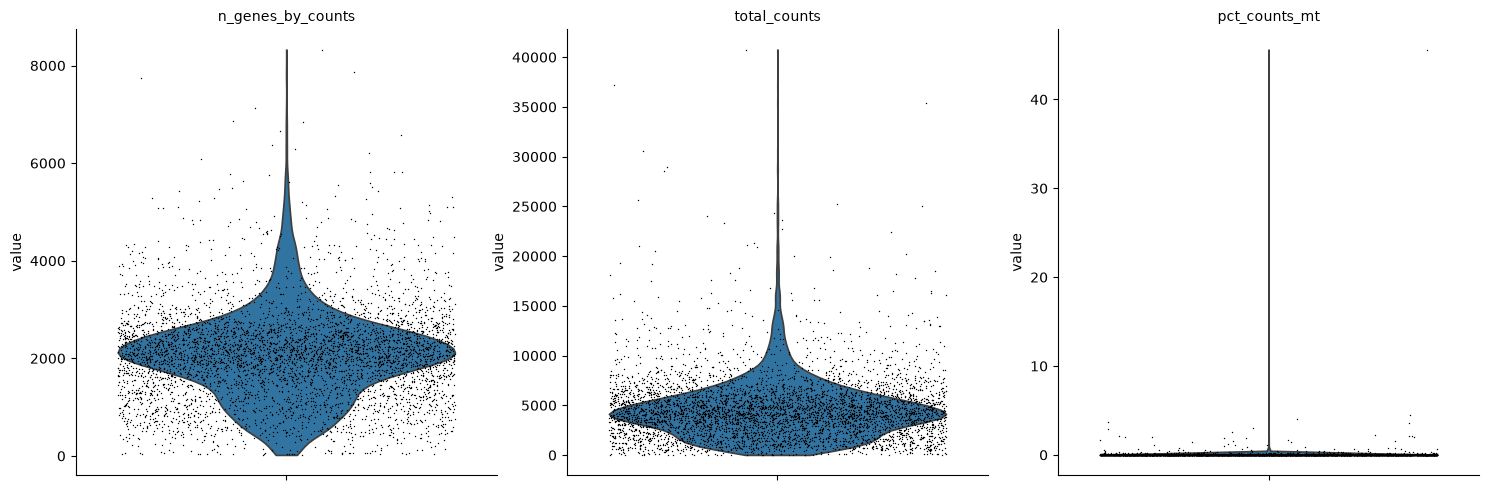

In [7]:
sc.pl.violin(
    normal_adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

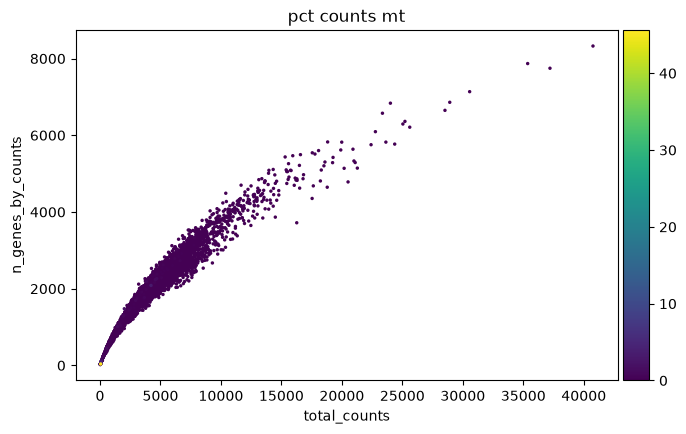

In [8]:
sc.pl.scatter(normal_adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

Normal dataset:
- from the scatter plot and the rightmost violin plot, mt genes are not significantly expressed in all cells
- around 2000 genes have nonzero expression values in most cells (leftmost violin)
- most cells have around 5000 counts (basically # transcripts mapped to gene) each according to the middle violin plot

In [9]:
# QC of reads under specific gene groups
tumor_adata.var["mt"] = tumor_adata.var_names.str.startswith("MT-")
# ribosomal genes
tumor_adata.var["ribo"] = tumor_adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
tumor_adata.var["hb"] = tumor_adata.var_names.str.contains("^HB[^(P)]")

In [10]:
sc.pp.calculate_qc_metrics(tumor_adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

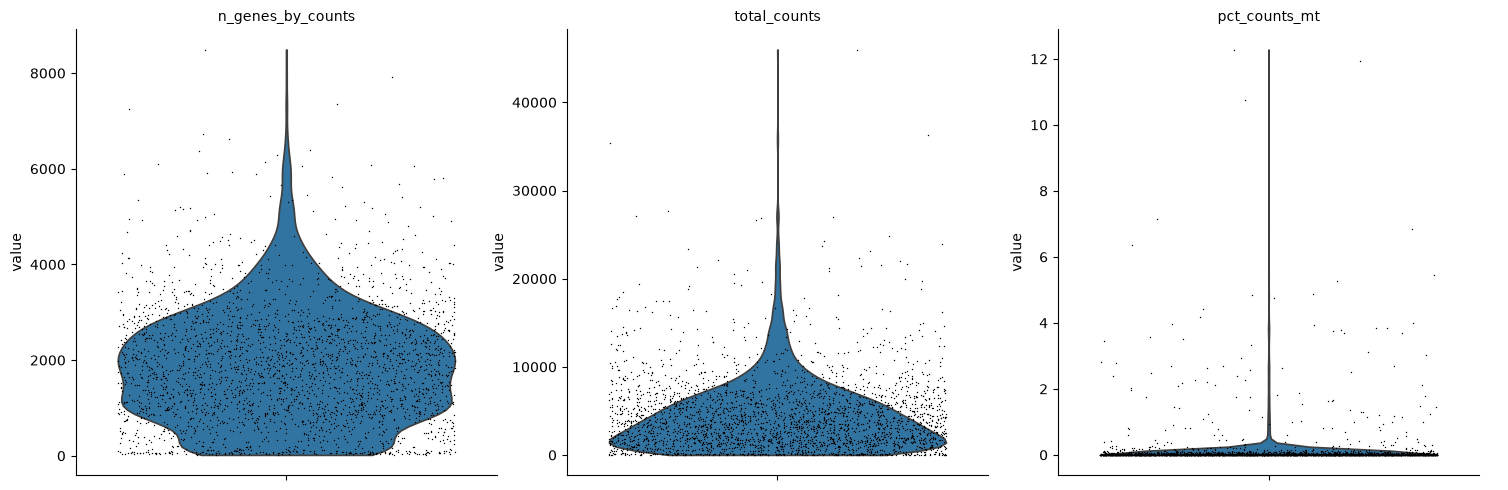

In [11]:
sc.pl.violin(
    tumor_adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

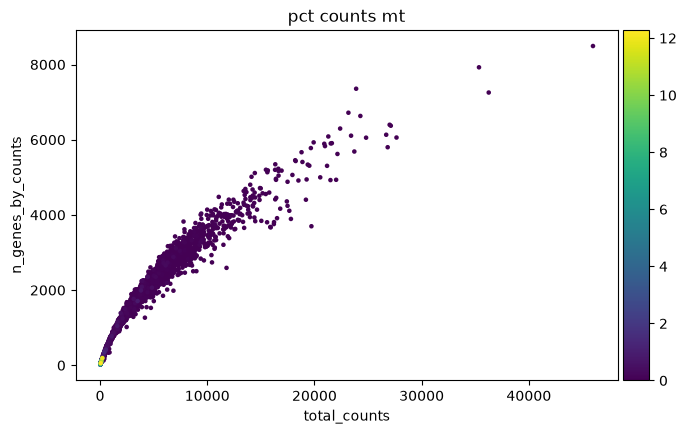

In [12]:
sc.pl.scatter(tumor_adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

tumor cells:
- higher number of cells with higher % of mt genes expressed
    - No filtering will be done on this as cancer cells can have higher metabolism 
- decreased total counts per cell in general
- still around 2000 genes expressed per cell

### doublet detection/annotation

In [13]:
sc.pp.scrublet(normal_adata)
sc.pp.scrublet(tumor_adata)

### Combining tumoral and mtched norml dtasets for downstream processing

In [14]:
normal_adata

AnnData object with n_obs × n_vars = 4927 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)

In [15]:
tumor_adata

AnnData object with n_obs × n_vars = 2780 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)

In [16]:
combined_adata = ad.concat({"normal":normal_adata, "tumor":tumor_adata}, label="group")
combined_adata

C:\Users\David\AppData\Local\Temp\ipykernel_29128\2777681898.py:1: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  combined_adata = ad.concat({"normal":normal_adata, "tumor":tumor_adata}, label="group")


AnnData object with n_obs × n_vars = 7707 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'group'
    layers: None (.X)

### Normalization

In [17]:
# save og counts
combined_adata.layers["counts"] = combined_adata.X.copy()

In [18]:
# regular log normalization
combined_adata.layers["log1p"] = np.log1p(combined_adata.X)

In [19]:
# Normalizing to median total counts per cell
# Despite the slightly imbalanced dataset the normalization process is unaffected
sc.pp.normalize_total(combined_adata)
# Logarithmize the data
sc.pp.log1p(combined_adata)
combined_adata.layers["log1PF"] = combined_adata.X.copy()

In [20]:
combined_adata

AnnData object with n_obs × n_vars = 7707 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'group'
    uns: 'log1p'
    layers: None (.X), 'counts', 'log1p', 'log1PF'

## Analyses

### Highly Variable Genes (HVGs) across tumor and normal samples 

Because Highly-variable genes (HVGs) compare across experimental groups, we need to consider
the sizes of our groups (2000 vs. 4900 samples). The imbalance means that the batch_key parameter
is needed to compute HVGs by GROUP to avoid overfitting to the majority group

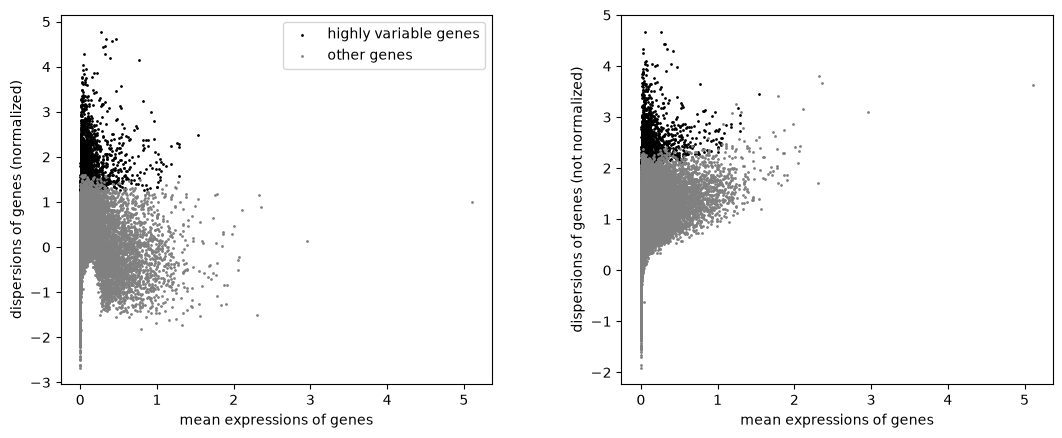

In [21]:
# IMPORTANT - make sure X layer is the log1pf data before running this cell
# annotate log1pf layer with top 2000 highly variable genes
sc.pp.highly_variable_genes(combined_adata, n_top_genes=2000, batch_key="group")
# plotting
sc.pl.highly_variable_genes(combined_adata)

### PCA and UMAP

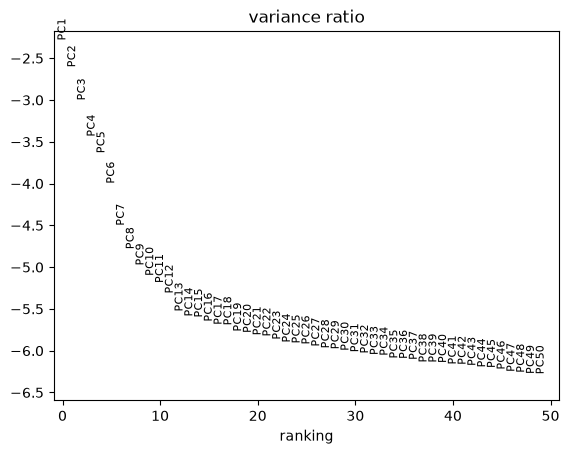

7 PCs capture most of the data, but 4 PCs can give a good estimate


In [22]:
sc.tl.pca(combined_adata)
sc.pl.pca_variance_ratio(combined_adata, n_pcs=50, log=True)
print("7 PCs capture most of the data, but 4 PCs can give a good estimate")

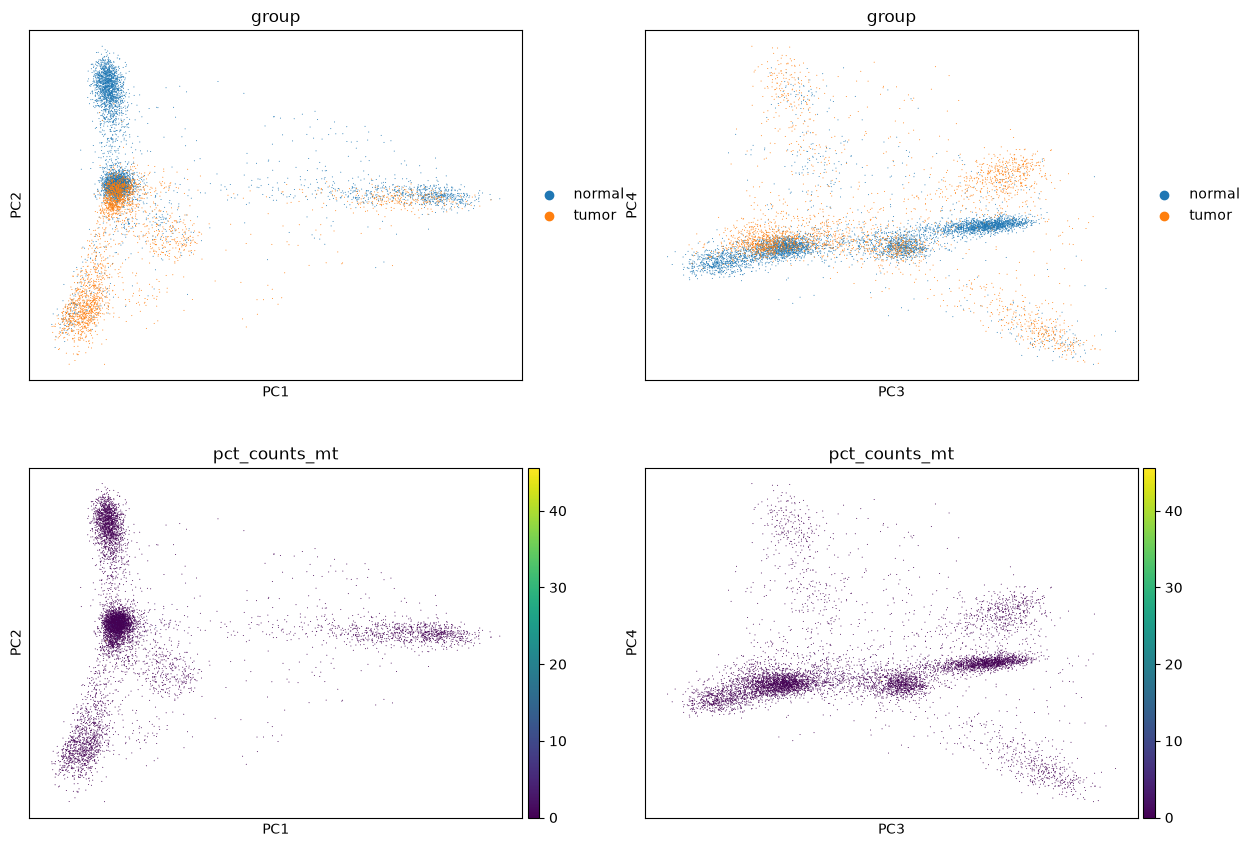

In [23]:
sc.pl.pca(
    combined_adata,
    # display %of mitochondrial genes expressed in counts according to different PC's
    # also displays PC informative nature by experimental group
    color=["group", "group", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

Interpretations? 
- first 4 PCs can demonstrate significant differences between tumoral and normal tissues
- however, they do not capture differences in mitochondrial gene expression between the groups
    - maybe the mt count changes are minor in terms of overall counts?
    - does ignoring mt count information have other consequences (biological significance?)

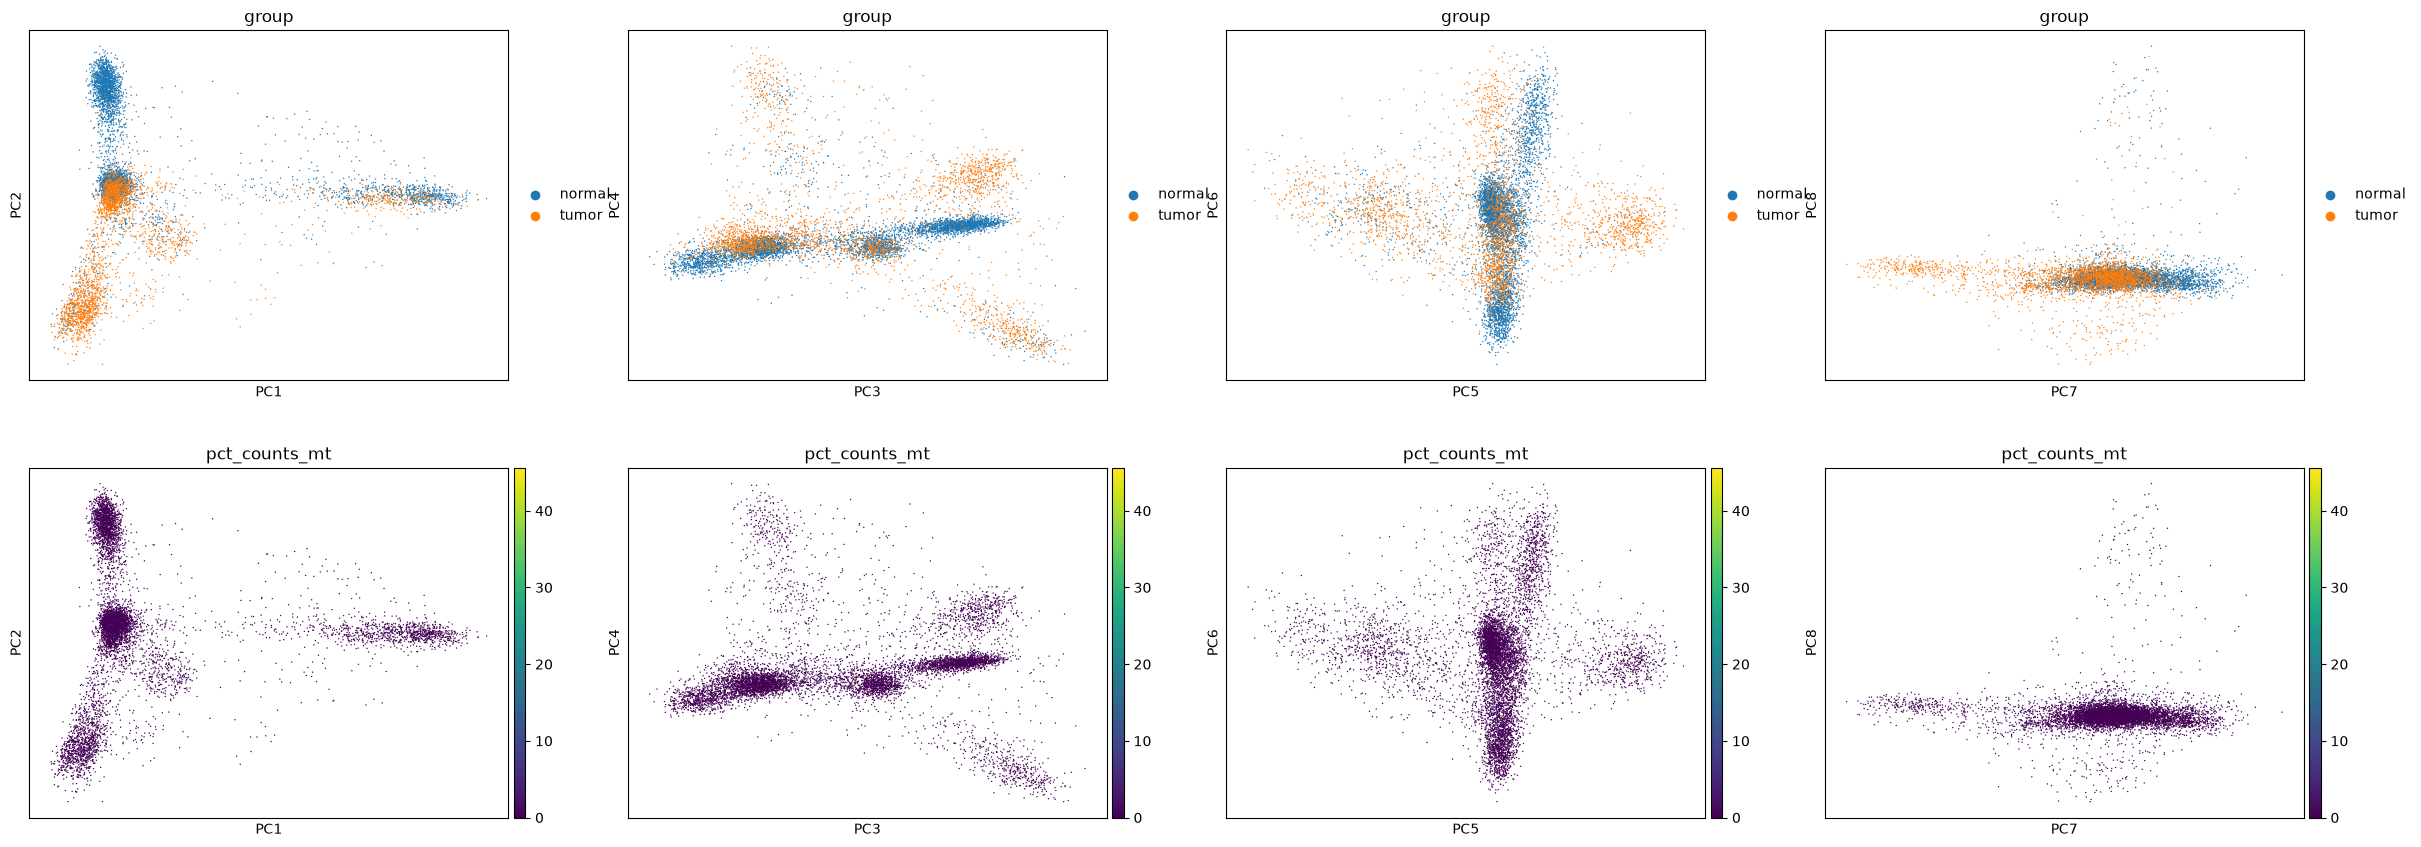

In [24]:
# try plotting the first 8 PC's now!
sc.pl.pca(
    combined_adata,
    # display %of mitochondrial genes expressed in counts according to different PC's
    # also displays PC informative nature by experimental group
    color=["group", "group", "group", "group", "pct_counts_mt", "pct_counts_mt", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (4, 5), (6, 7), (0,1), (2,3), (4,5), (6,7)],
    ncols=4,
    size=4,
)

The percentage of mitochondrial counts still stays at 0 across all 8 PC's
- only small proportional of tumoral cells have elevated %mtcounts, but need to be careful of these
cells' potential effects in the tumor micro-environment.

### 2D UMAP of PCA representation

c:\Users\David\anaconda3\envs\JupyterEnv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


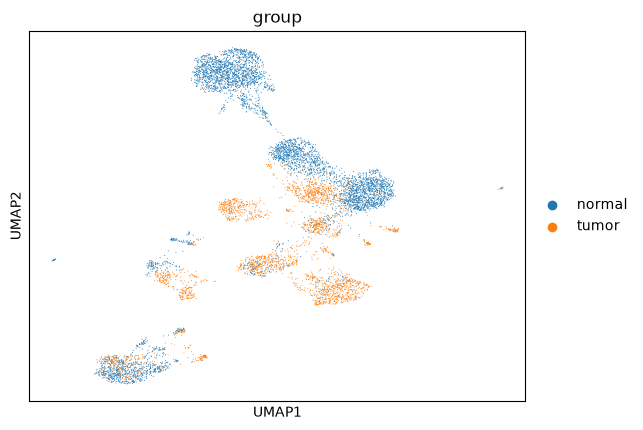

In [25]:
sc.pp.neighbors(combined_adata)
sc.tl.umap(combined_adata)
sc.pl.umap(
    combined_adata,
    color="group",
    size=2
)

Hard to conclude potential batch effects on the samples as the samples came from 1 patient only and
we expect to see marked differences in expression b/w the groups

### leiden clustering

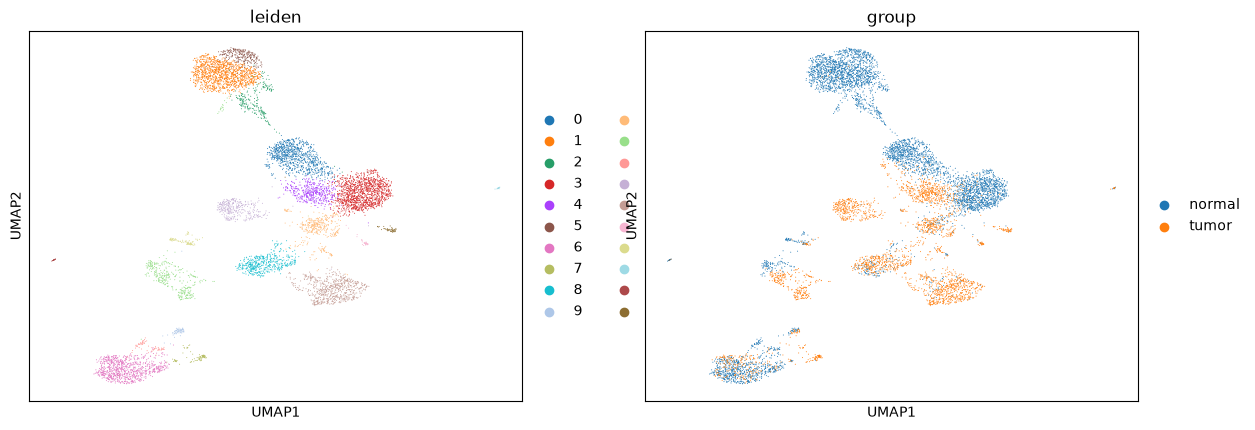

In [26]:
# leiden clustering - clustering based on modularity optimization (Traag et al., 2019)
# and the neighbourhood graph of cells
sc.tl.leiden(combined_adata, flavor="igraph", n_iterations=2)
sc.pl.umap(combined_adata, color=["leiden", "group"], size=2)

Some Leiden clusters overlap well with tumor cells (groups 4, 13, 19), 
but most groups contain a mix of normal/tumoral cells

### PHATE - another clustering algo that keeps local and global interctions
- good for seeing cellular differntiation/continual progressions (Moon et al., 2017)

In [27]:
import phate

sc.external.tl.phate(
    combined_adata,
    n_components=2,
    knn_dist="euclidean",
    t="auto"
)

c:\Users\David\anaconda3\envs\JupyterEnv\Lib\site-packages\phate\phate.py:208: FutureWarning: k is deprecated. Please use knn in future.
  warnings.warn("k is deprecated. Please use knn in future.", FutureWarning)
c:\Users\David\anaconda3\envs\JupyterEnv\Lib\site-packages\phate\phate.py:212: FutureWarning: a is deprecated. Please use decay in future.
  warnings.warn("a is deprecated. Please use decay in future.", FutureWarning)


    SGD-MDS may not have converged: stress changed by -2.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.


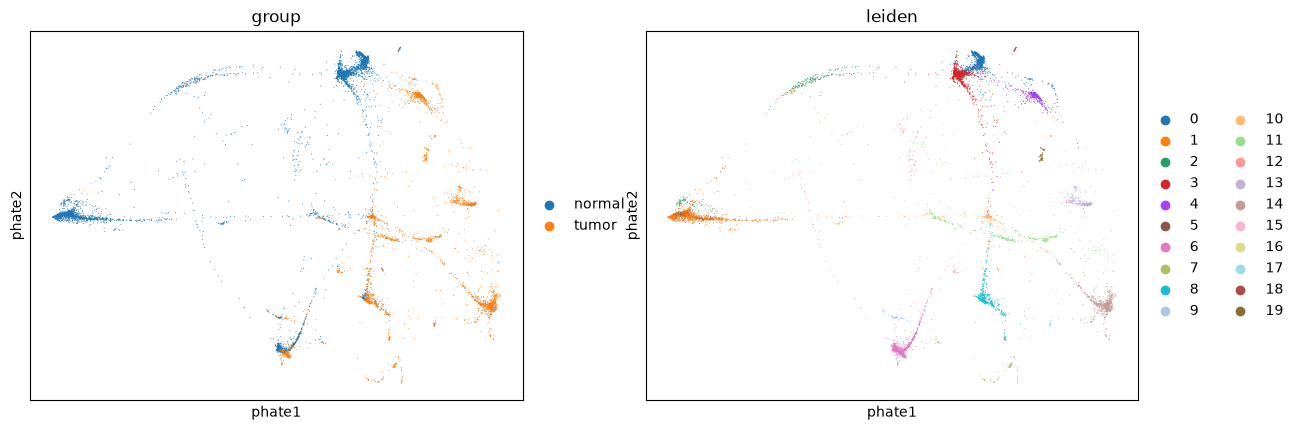

In [28]:
sc.external.pl.phate(
    combined_adata,
    color=["group", "leiden"],
    size=2
)

Larger differences between normal/tumor groups are apparent in the phate representation
- However it is still difficuilt to interpret meaning of leiden clusters

In [29]:
# Saving anndata object as .h5ad
combined_adata.write_h5ad("./data/scRNA/normalized_combined_counts.h5ad", compression="gzip", compression_opts=9)

### QC metrics-based plots

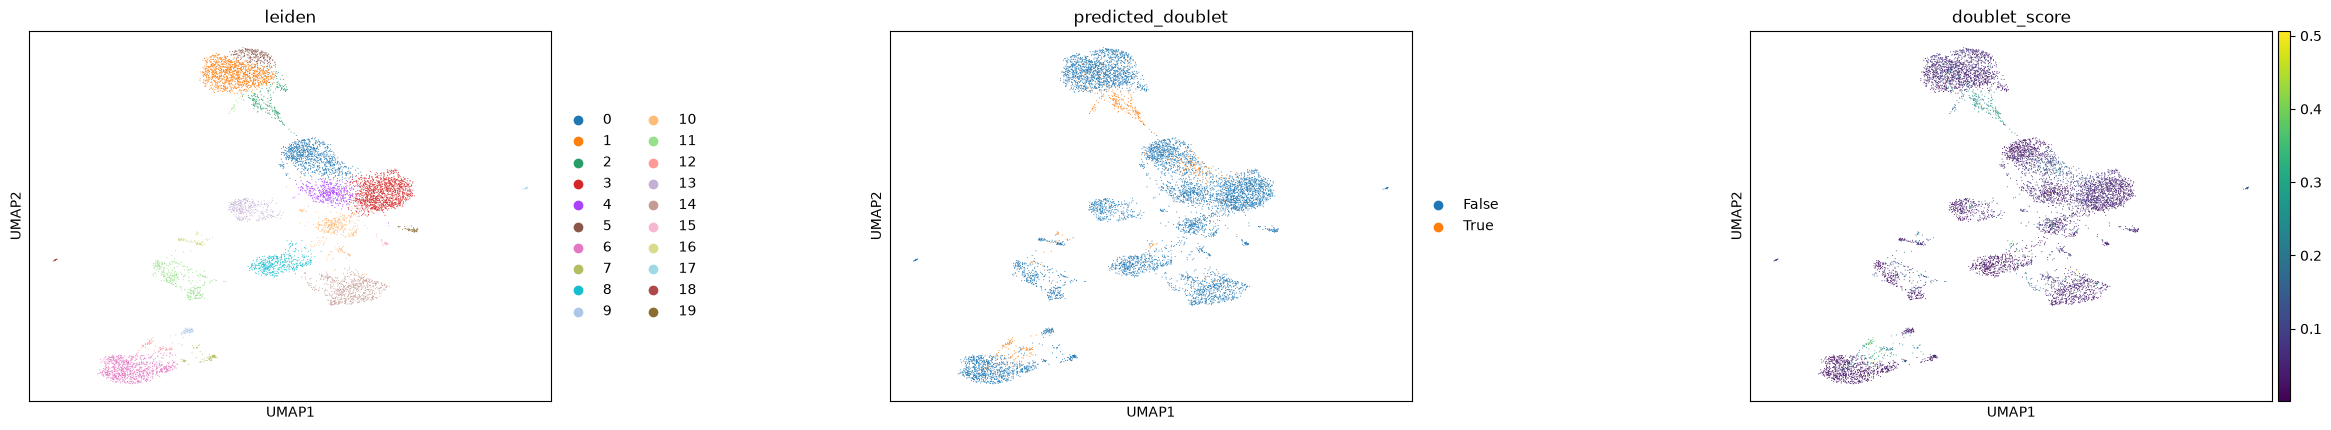

In [30]:
sc.pl.umap(
    combined_adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=2
)

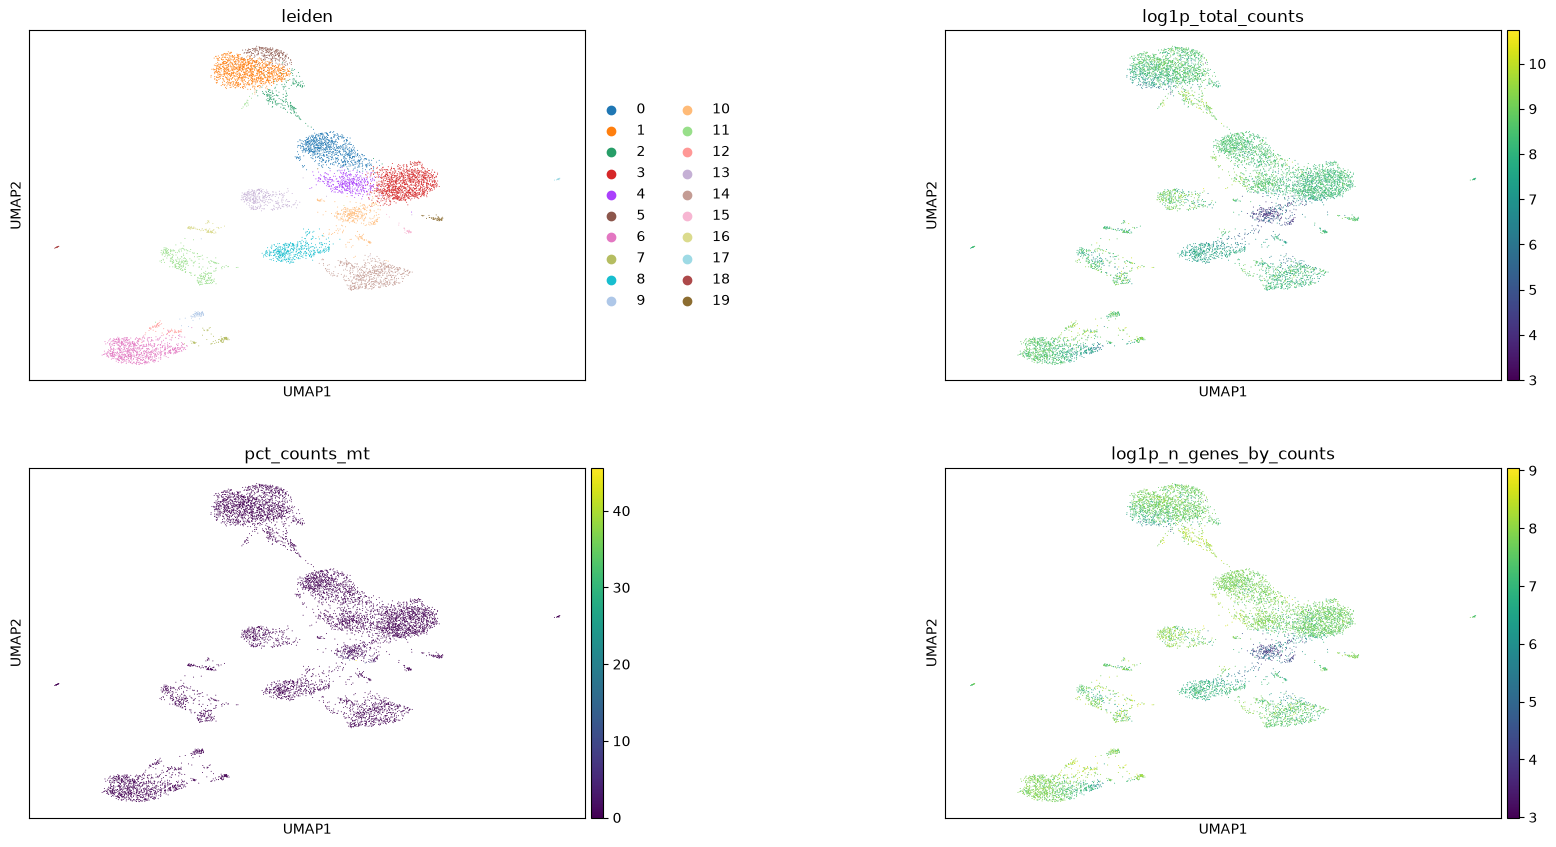

In [31]:
sc.pl.umap(
    combined_adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
    size=2
)

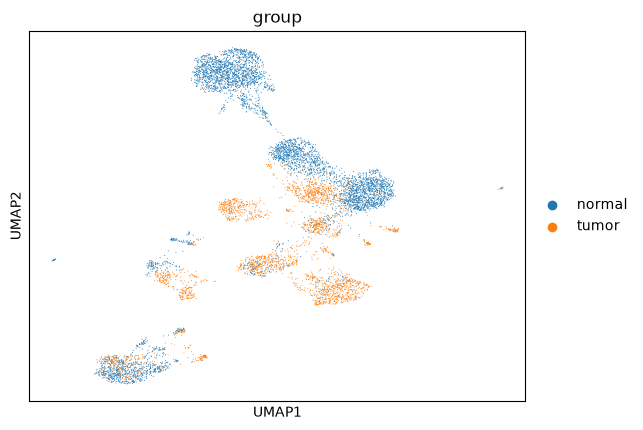

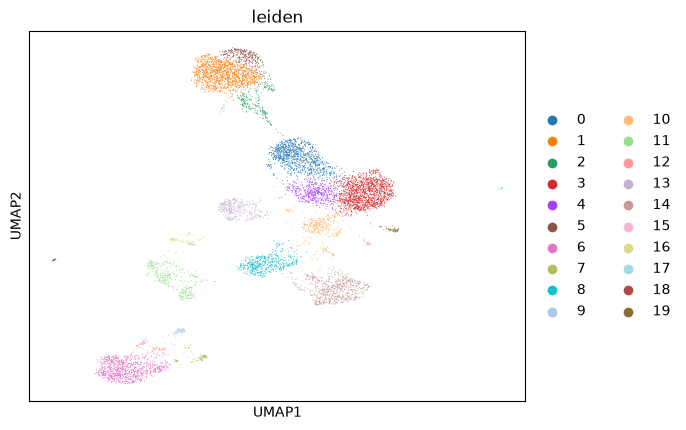

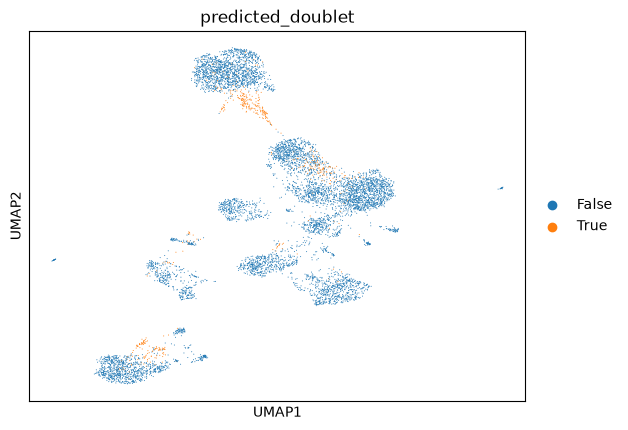

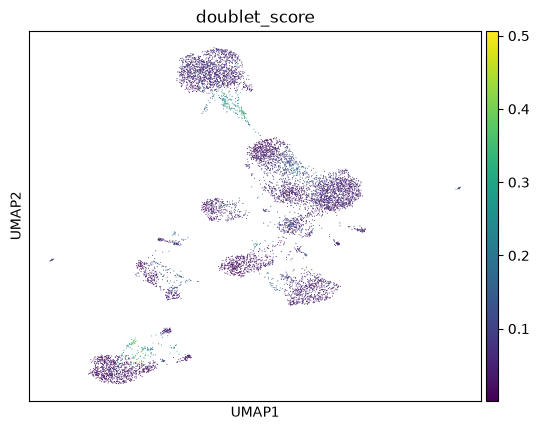

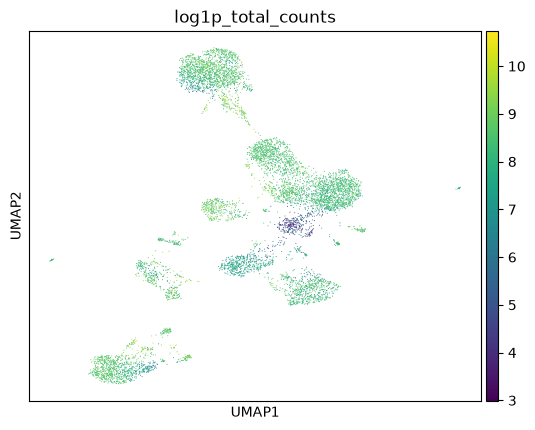

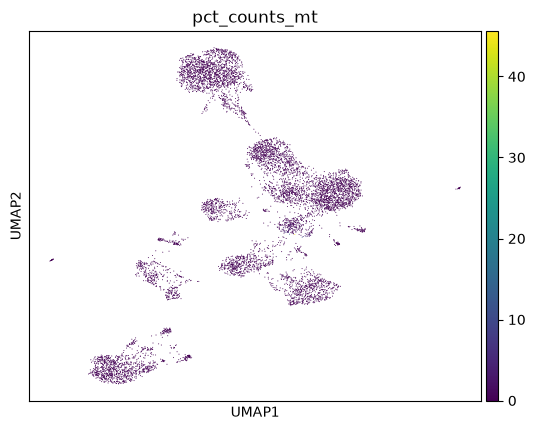

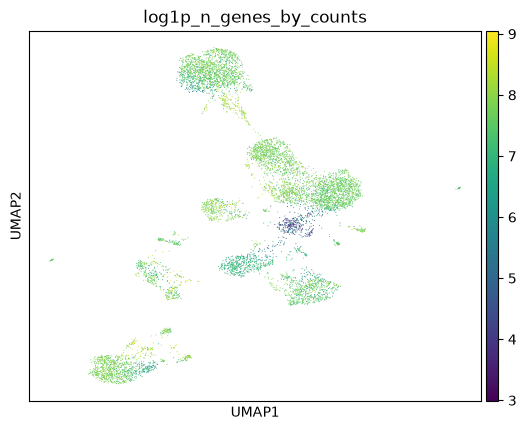

In [32]:
# saving plots
for metric in ["group", "leiden","predicted_doublet", "doublet_score", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"]:
    sc.pl.umap(combined_adata, color=[metric], size=2, show=False).figure.savefig(f"./data/figures/{metric}.pdf", bbox_inches="tight")


## CHECKPOINT: read .h5ad file saved to resume from here


In [33]:

# combined_adata = sc.read_h5ad("./data/scRNA/normalized_combined_counts.h5ad")

In [34]:
combined_adata

AnnData object with n_obs × n_vars = 7707 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'group', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg', 'pca', 'group_colors', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'predicted_doublet_colors'
    obsm: 'X_pca', 'X_umap', 'X_phate'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts', 'log1p', 'log1PF'

## comparison of HVGs (intragroup) vs. DEGs (intergroup)

In [35]:
# INTRA-group normalizations
normal_adata.layers["intragroup_counts"] = normal_adata.X.copy()
normal_adata.layers["intragroup_log1p"] = np.log1p(normal_adata.X)

sc.pp.normalize_total(normal_adata)
sc.pp.log1p(normal_adata)
normal_adata.layers["intragroup_log1pf"] = normal_adata.X.copy()

In [36]:
# INTRA-group HVGs (top 1000)
sc.pp.highly_variable_genes(normal_adata, n_top_genes=1000)
normal_adata

AnnData object with n_obs × n_vars = 4927 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'log1p', 'hvg'
    layers: None (.X), 'intragroup_counts', 'intragroup_log1p', 'intragroup_log1pf'

In [37]:
# INTRA-group normalizations
tumor_adata.layers["intragroup_counts"] = tumor_adata.X.copy()
tumor_adata.layers["intragroup_log1p"] = np.log1p(tumor_adata.X)

sc.pp.normalize_total(tumor_adata)
sc.pp.log1p(tumor_adata)
tumor_adata.layers["intragroup_log1pf"] = tumor_adata.X.copy()

In [38]:
#INTRA-group HVGs (top 1000)
sc.pp.highly_variable_genes(tumor_adata, n_top_genes=1000)
tumor_adata

AnnData object with n_obs × n_vars = 2780 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'log1p', 'hvg'
    layers: None (.X), 'intragroup_counts', 'intragroup_log1p', 'intragroup_log1pf'

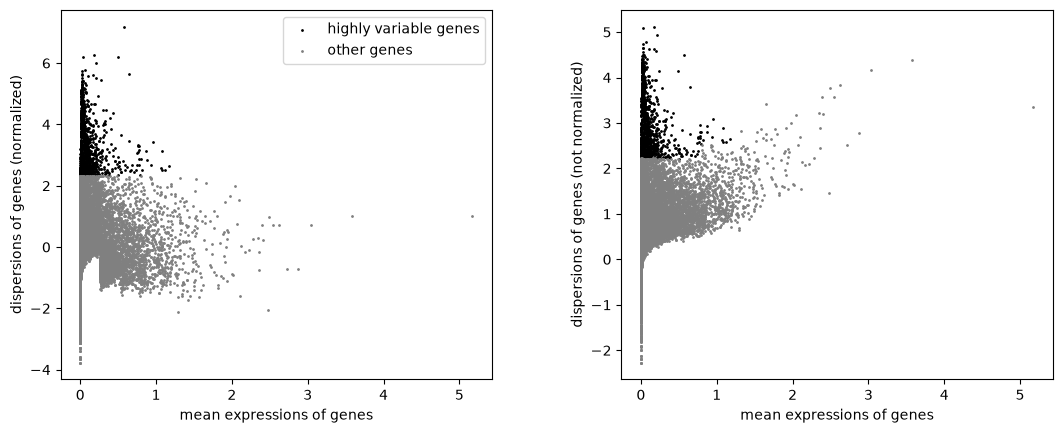

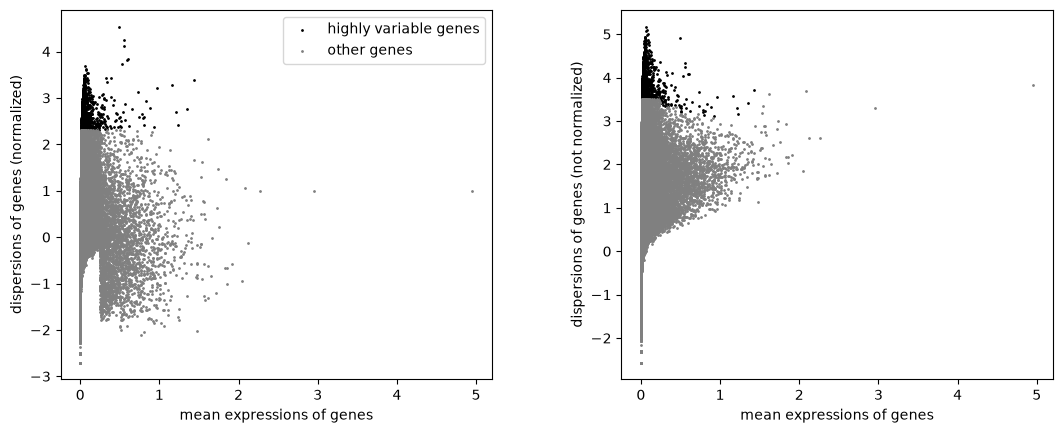

In [39]:
sc.pl.highly_variable_genes(normal_adata)
sc.pl.highly_variable_genes(tumor_adata)

In [40]:
normal_adata.var["psuedobulk"] = np.array(normal_adata.layers["intragroup_counts"].sum(axis=0)).flatten()
tumor_adata.var["psuedobulk"] = np.array(tumor_adata.layers["intragroup_counts"].sum(axis=0)).flatten()

In [41]:
normal_bulk_df = pd.DataFrame(normal_adata.var["psuedobulk"]).transpose()
tumor_bulk_df = pd.DataFrame(tumor_adata.var["psuedobulk"]).transpose()
combined_bulk_df = pd.concat([normal_bulk_df, tumor_bulk_df])
combined_bulk_df.index = ["normal", "tumor"]
combined_bulk_df

,MIR1302-2HG,FAM138A,OR4F5,AL627309.1,AL627309.3,AL627309.2,AL627309.5,AL627309.4,AP006222.2,AL732372.1,...,AC133551.1,AC136612.1,AC136616.1,AC136616.3,AC136616.2,AC141272.1,AC023491.2,AC007325.1,AC007325.4,AC007325.2
normal,0.0,0.0,0.0,32.0,0.0,3.0,127.0,5.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,29.0,13.0
tumor,0.0,0.0,0.0,28.0,0.0,0.0,71.0,5.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,3.0


In [42]:
import pydeseq2

metadata_df = pd.concat([combined_bulk_df[[]], pd.DataFrame({"normal":["normal"], "tumor":["tumor"]}).transpose()], axis=1)
metadata_df.columns = ["group"]
metadata_df

,group
normal,normal
tumor,tumor


In [43]:
# filtering out genes that have 0 bulk expression across our 2 sampples

nonzero_genes = combined_bulk_df.columns[combined_bulk_df.sum(axis=0) > 0]
combined_bulk_df = combined_bulk_df[nonzero_genes]
combined_bulk_df

,AL627309.1,AL627309.2,AL627309.5,AL627309.4,AP006222.2,AC114498.1,AL669831.2,LINC01409,LINC01128,LINC00115,...,AL354822.1,AL592183.1,AC240274.1,AC213203.2,AC004556.3,AC233755.2,AC136352.3,AC023491.2,AC007325.4,AC007325.2
normal,32.0,3.0,127.0,5.0,2.0,2.0,0.0,357.0,601.0,43.0,...,246.0,2353.0,128.0,1.0,8.0,0.0,1.0,2.0,29.0,13.0
tumor,28.0,0.0,71.0,5.0,1.0,0.0,6.0,295.0,220.0,21.0,...,158.0,804.0,114.0,0.0,8.0,1.0,0.0,0.0,8.0,3.0


In [44]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

inference = DefaultInference()
dds = DeseqDataSet(
    counts= combined_bulk_df,
    metadata= metadata_df,
    design="~group",
    refit_cooks=True,
    inference=inference
)

Because of the lack of enoguh samples, deseq2 cannot be run from 1 normal bulk and 1 tumor bulk

In [45]:
# explortion of intra-group HVGs vs. HVGs across both groups
normal_HVGs = normal_adata.var[normal_adata.var["highly_variable"] == True].index.transpose()
normal_HVGs

Index(['ATAD3C', 'AL139246.3', 'TAS1R1', 'SLC25A33', 'AL031731.1', 'MTHFR',
       'TNFRSF1B', 'CELA2A', 'PLEKHM2', 'CPLANE2',
       ...
       'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3',
       'MT-ND4', 'MT-CYB', 'AC240274.1'],
      dtype='str', length=1000)

In [46]:
tumor_HVGs = tumor_adata.var[tumor_adata.var["highly_variable"] == True].index.transpose()
tumor_HVGs

Index(['PUSL1', 'MRPL20', 'CALML6', 'AL590822.1', 'PRXL2B', 'SLC25A33',
       'FBXO2', 'KIAA2013', 'TNFRSF8', 'AGMAT',
       ...
       'AC011751.1', 'MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP6',
       'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-CYB'],
      dtype='str', length=1000)

In [47]:
# compare the HVGs par groupe!
common_HVGs = set(normal_HVGs) & set(tumor_HVGs)
print(f"Number of common genes: {len(common_HVGs)}")

Number of common genes: 84


In [48]:
normal_only_HVGs = set(normal_HVGs) - set(tumor_HVGs)
tumor_only_HVGs = set(tumor_HVGs) - set(normal_HVGs)

print(f"Number of unique HVGs in normal sample: {len(normal_only_HVGs)}\nNumber of unique HVGs in tumor sample: {len(tumor_only_HVGs)}")

Number of unique HVGs in normal sample: 916
Number of unique HVGs in tumor sample: 916


### GOterm functional analyses of unique HVGs in each group

In [49]:
import gseapy

# I assume this is less informative than the tumor-specific HVGs
enr_normal = gseapy.enrichr(
    gene_list=list(normal_only_HVGs),
    gene_sets=['GO_Biological_Process_2023'],
    organism='human'
)

enr_tumor = gseapy.enrichr(
    gene_list=list(tumor_only_HVGs),
    gene_sets=['GO_Biological_Process_2023'],
    organism='human'
)

In [50]:
tumor_GO_df = enr_tumor.results
tumor_GO_significant = tumor_GO_df[tumor_GO_df["Adjusted P-value"] < 0.05]
tumor_GO_significant


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2023,Cytoplasmic Translation (GO:0002181),16/93,0.000005,0.01043,0,0,4.388341,53.97173,RPS7;RPL10;RPS5;RPL12;RPS6;RPL35A;RPS16;RPL18A...


Only 1 GO process is significant from the tumor subgroup, what about in the normal-specific GO's?

In [51]:
normal_GO_df = enr_normal.results
normal_GO_significant = normal_GO_df[normal_GO_df["Adjusted P-value"]<0.05]
normal_GO_significant

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes


No significant GO terms for the normal-specific HVGs - what about the overlapped HVGs?

In [52]:
enr_overlap = gseapy.enrichr(
    gene_list=list(common_HVGs),
    gene_sets=['GO_Biological_Process_2023'],
    organism='human'
)

common_GO_df = enr_overlap.results
common_GO_significant = common_GO_df[common_GO_df["Adjusted P-value"]<0.05]
common_GO_significant

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2023,Cytoplasmic Translation (GO:0002181),8/93,5.250653e-09,0.000003,0,0,24.558514,468.205940,RPS17;RPS28;RPS15A;RPL34;RPL27A;RPL35;RPL13A;R...
1,GO_Biological_Process_2023,Peptide Biosynthetic Process (GO:0043043),8/158,3.328758e-07,0.000104,0,0,13.870877,206.891017,RPS17;RPS28;RPS15A;RPL34;RPL27A;RPL35;RPL13A;R...
2,GO_Biological_Process_2023,Translation (GO:0006412),9/234,6.052399e-07,0.000126,0,0,10.501867,150.361955,RPS17;RPS28;RPS15A;RPL34;RPL27A;RPL35;RPL13A;R...
3,GO_Biological_Process_2023,Macromolecule Biosynthetic Process (GO:0009059),8/183,1.015603e-06,0.000159,0,0,11.874286,163.865470,RPS17;RPS28;RPS15A;RPL34;RPL27A;RPL35;RPL13A;R...
4,GO_Biological_Process_2023,Gene Expression (GO:0010467),9/296,4.204008e-06,0.000526,0,0,8.207247,101.601390,RPS17;RPS28;NUFIP1;RPS15A;RPL34;RPL27A;RPL35;R...
5,GO_Biological_Process_2023,Regulation Of Reactive Oxygen Species Biosynth...,3/26,1.732875e-04,0.018080,0,0,32.033816,277.430748,PLCG2;SLC25A33;INS
6,GO_Biological_Process_2023,Regulation Of Transmembrane Transport (GO:0034...,3/32,3.246256e-04,0.029031,0,0,25.398467,204.021773,KCNJ6;ACTB;INS
7,GO_Biological_Process_2023,Regulation Of Transmembrane Transporter Activi...,2/9,6.155963e-04,0.048170,0,0,69.369338,512.841908,ACTB;INS


More significant GO terms found in shared HVGs!
- Maybe this process should be done with DEGs instead
    - Ideas: add counts from groups of cells and treat them as individuals within the same group to run DEG?